# F1 Lap-Time Performance Analysis

This project analyses lap-time data for two drivers using Python, pandas and Matplotlib.

The aim is to compare average lap times, fastest laps and performance across successive laps.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
f1_data_set =  pd.read_csv('lap_data.csv')   
f1_data_set

,driver,lap_number,lap_time,tyre
0,Driver A,1,92.4,Soft
1,Driver A,2,91.8,Soft
2,Driver A,3,91.5,Soft
3,Driver A,4,91.7,Soft
4,Driver A,5,92.0,Soft
5,Driver B,1,93.1,Medium
6,Driver B,2,92.6,Medium
7,Driver B,3,92.2,Medium
8,Driver B,4,92.4,Medium
9,Driver B,5,92.8,Medium


In [3]:
f1_data_set.head()

,driver,lap_number,lap_time,tyre
0,Driver A,1,92.4,Soft
1,Driver A,2,91.8,Soft
2,Driver A,3,91.5,Soft
3,Driver A,4,91.7,Soft
4,Driver A,5,92.0,Soft


In [4]:
print(len(f1_data_set)) 
## number of rows 

print(f1_data_set.columns)

10
Index(['driver', 'lap_number', 'lap_time', 'tyre'], dtype='str')


## Checking the data

I am checking whether any values are missing.

In [5]:
f1_data_set.isna().sum()

driver        0
lap_number    0
lap_time      0
tyre          0
dtype: int64

## Average lap time

I will calculate the average lap time for each driver.

A lower lap time means a faster driver.

In [6]:
#Group the data by driver
driver_groups = f1_data_set.groupby("driver")

# Select the lap_time column and calculate the average
average_lap_time = driver_groups["lap_time"].mean()

# Display the result
print("Average lap time for each driver:")
print(average_lap_time)

Average lap time for each driver:
driver
Driver A    91.88
Driver B    92.62
Name: lap_time, dtype: float64


## Fastest lap

Now I will find the fastest lap for each driver.

The smallest number is the fastest lap.

In [7]:
# Find the smallest lap time for each driver
fastest_lap_time = driver_groups["lap_time"].min()

print("Fastest lap for each driver:")
print(fastest_lap_time)

Fastest lap for each driver:
driver
Driver A    91.5
Driver B    92.2
Name: lap_time, dtype: float64


Slowest lap

In [8]:
# Find the largest lap time for each driver
slowest_lap_time = driver_groups["lap_time"].max()

print("Slowest lap for each driver:")
print(slowest_lap_time)

Slowest lap for each driver:
driver
Driver A    92.4
Driver B    93.1
Name: lap_time, dtype: float64


## Lap-time range

The lap-time range shows the difference between a driver's slowest and fastest lap.

A larger range means the lap times varied more in this dataset.

In [9]:
# Calculate the difference between the slowest and fastest lap
lap_time_range = slowest_lap_time - fastest_lap_time

print("Lap-time range for each driver:")
print(lap_time_range)

Lap-time range for each driver:
driver
Driver A    0.9
Driver B    0.9
Name: lap_time, dtype: float64


## Separating the drivers

I will create a separate table for each driver.

To make it easier to draw both drivers on the same chart.

In [10]:
# Keep only the rows for Driver A
driver_a_data = f1_data_set[f1_data_set["driver"] == "Driver A"]

# Keep only the rows for Driver B
driver_b_data = f1_data_set[f1_data_set["driver"] == "Driver B"]

print("Driver A:")
display(driver_a_data)

print("Driver B:")
display(driver_b_data)

Driver A:


,driver,lap_number,lap_time,tyre
0,Driver A,1,92.4,Soft
1,Driver A,2,91.8,Soft
2,Driver A,3,91.5,Soft
3,Driver A,4,91.7,Soft
4,Driver A,5,92.0,Soft


Driver B:


,driver,lap_number,lap_time,tyre
5,Driver B,1,93.1,Medium
6,Driver B,2,92.6,Medium
7,Driver B,3,92.2,Medium
8,Driver B,4,92.4,Medium
9,Driver B,5,92.8,Medium


## Lap time across the laps

This line chart shows how each driver's lap time changed from lap 1 to lap 5.

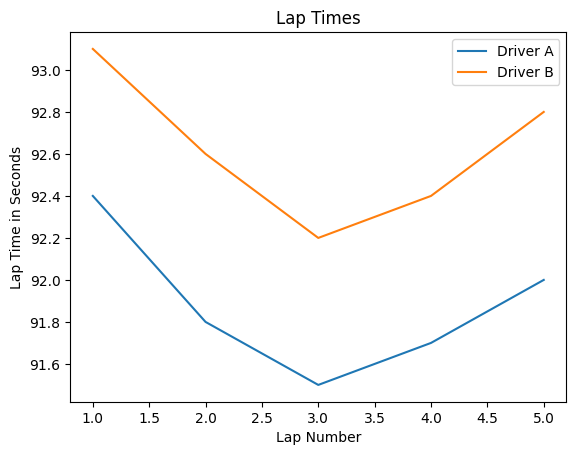

In [11]:

laps_a = driver_a_data["lap_number"]
laps_b = driver_b_data["lap_number"]


times_a = driver_a_data["lap_time"]
times_b = driver_b_data["lap_time"]


plt.plot(laps_a, times_a, label="Driver A")
plt.plot(laps_b, times_b, label="Driver B")


plt.title("Lap Times")
plt.xlabel("Lap Number")
plt.ylabel("Lap Time in Seconds")




plt.legend()
plt.show()

## Average lap time chart

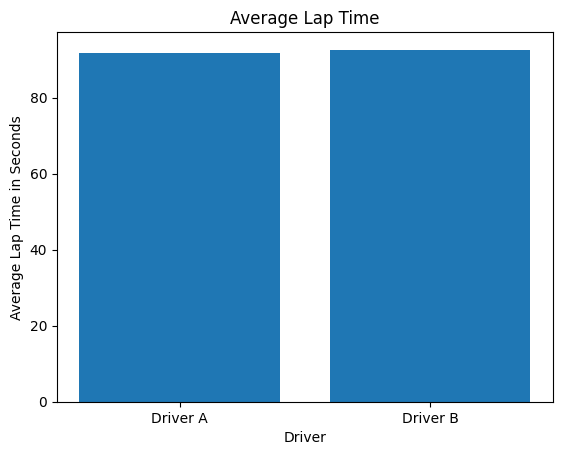

In [12]:

driver_names = average_lap_time.index


average_times = average_lap_time.values


plt.bar(driver_names, average_times)
plt.title("Average Lap Time")
plt.xlabel("Driver")
plt.ylabel("Average Lap Time in Seconds")


plt.show()

## Fastest lap chart

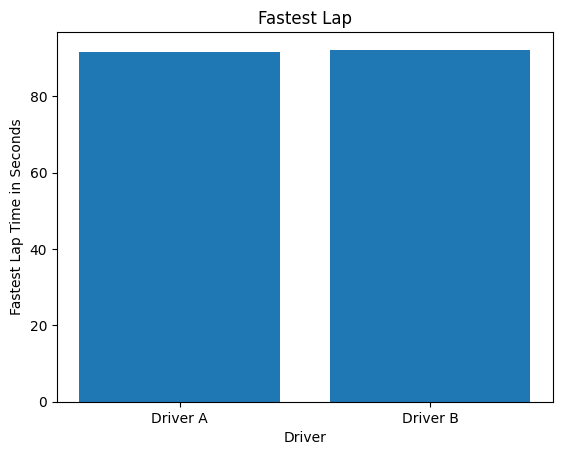

In [13]:

fastest_times = fastest_lap_time.values


plt.bar(driver_names, fastest_times)
plt.title("Fastest Lap")
plt.xlabel("Driver")
plt.ylabel("Fastest Lap Time in Seconds")


plt.show()

## Findings

Driver A had the faster average lap time.

Driver A's average lap time was 91.88 seconds.
Driver B's average lap time was 92.62 seconds.

Driver A also recorded the fastest lap.
Driver A's fastest lap was 91.5 seconds.
Driver B's fastest lap was 92.2 seconds.

Driver A was faster than Driver B on every lap in this dataset.

However, this is only a small sample. The drivers also used different tyre compounds, so the comparison is not completely fair.

## Limitations

- The dataset contains only ten laps.
- The data is fictional and is not real Formula 1 telemetry.
- Driver A used Soft tyres and Driver B used Medium tyres.
- The analysis does not include fuel load, weather, traffic or track conditions.
- A larger dataset would be needed to make stronger conclusions.

## Conclusion

I used Python, pandas and Matplotlib to analyse lap-time data.

I calculated average lap times and fastest lap times.
I also created charts to compare the two drivers.

Driver A was faster than Driver B in this example.
However, the small dataset and different tyre compounds mean that this result should not be treated as a reliable comparison of real driver performance.